<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/03_Currency_Exchange_Impact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 03: Currency Exchange Impact on Irish Fuel

**Goal:** Investigate the macroeconomic hypothesis that a weaker Euro drives up domestic fuel prices in Ireland, independent of global oil market fluctuations.

**The Economic Context (The Exchange Rate Effect):**
1. **The Global Market Rule:** Crude oil is priced and traded globally in US Dollars (USD).
2. **The Local Reality:** Irish fuel suppliers and consumers pay for fuel in Euros (EUR).
3. **The Currency Trap:** If the global price of oil remains flat, but the Euro loses value against the Dollar, it requires more Euros to purchase the same barrel of oil.
4. **The Impact:** Suppliers pass this currency loss onto the consumer at the pump, acting as a hidden driver of grocery inflation.

This notebook uses Yahoo Finance data to cross-reference our CSO dataset with historical EUR/USD exchange rates to prove this inverse relationship.

In [3]:
!pip install yfinance -q

### 1. Fetching and Aligning the Datasets
We import our cleaned CSO fuel and grocery data directly from the project's GitHub repository. Simultaneously, we download the daily EUR/USD exchange rates spanning our exact 10-year project window (Jan 2016 - Jan 2026).

Because financial markets fluctuate daily but CSO data is aggregated monthly, we resample the daily currency rates into monthly averages so the two timelines align perfectly for correlation testing.

In [9]:
import pandas as pd
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt

# Set consistent project visualization style
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Load the cleaned CSO dataset from GitHub
url = 'https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/refs/heads/main/data/cleaned_fuel_grocery_data.csv'
df = pd.read_csv(url)

# Set the datetime index
df['Month_DT'] = pd.to_datetime(df['Month_DT'])
df.set_index('Month_DT', inplace=True)

# 2. Download historical EUR/USD exchange rates from Yahoo Finance
print("Fetching currency data from Yahoo Finance...")
eur_usd = yf.download('EURUSD=X', start='2016-01-01', end='2026-01-31', progress=False)

# 3. Extract the single Series, resample daily currency data to a monthly average (MS = Month Start)
eur_usd_series = eur_usd['Close']['EURUSD=X']
eur_usd_monthly = eur_usd_series.resample('MS').mean()
eur_usd_monthly.name = 'EUR_USD_Rate'

# 4. Merge the currency data with the CSO fuel/grocery dataset
merged_df = df.join(eur_usd_monthly, how='inner')

# Validate the merge
print(f"Merged dataset shape: {merged_df.shape}")
print("\n--- Data Sample ---")
print(merged_df[['Diesel', 'Petrol', 'EUR_USD_Rate']].head())

Fetching currency data from Yahoo Finance...
Merged dataset shape: (121, 6)

--- Data Sample ---
            Diesel  Petrol  EUR_USD_Rate
2016-01-01    65.0    72.8      1.086736
2016-02-01    61.1    70.5      1.109919
2016-03-01    61.9    70.0      1.111985
2016-04-01    64.2    73.1      1.133916
2016-05-01    65.3    74.7      1.131403


/tmp/ipykernel_588/2624141457.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  eur_usd = yf.download('EURUSD=X', start='2016-01-01', end='2026-01-31', progress=False)


### 2. Statistical Proof: The Correlation Matrix
We apply a Pearson correlation matrix to the merged dataset. We are looking for a **negative correlation** between the `EUR_USD_Rate` and fuel prices (`Petrol`, `Diesel`).

A negative score (closer to -1.0) mathematically proves that as the Euro's value decreases, the price of Irish fuel increases.

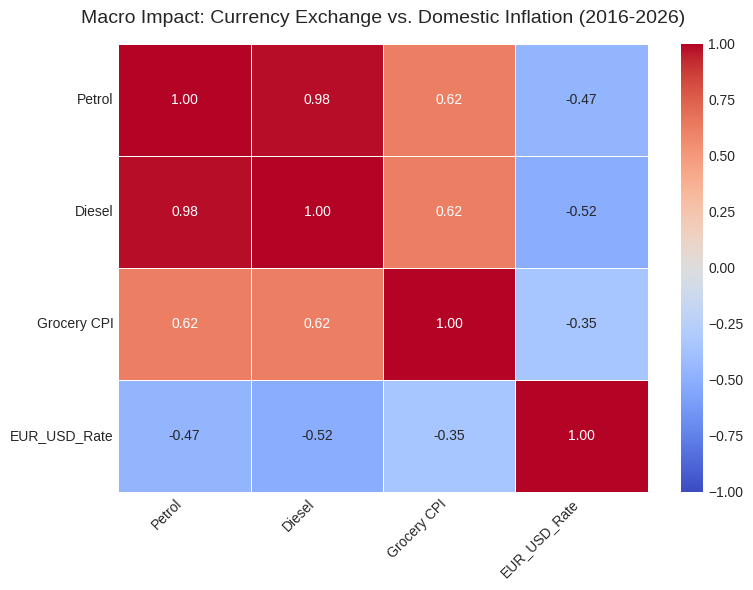

In [10]:
# Calculate the correlation matrix
correlation_matrix = merged_df[['Petrol', 'Diesel', 'Food and non-alcoholic beverages', 'EUR_USD_Rate']].corr()

# Rename the long CPI column for a cleaner chart layout
correlation_matrix = correlation_matrix.rename(
    columns={'Food and non-alcoholic beverages': 'Grocery CPI'},
    index={'Food and non-alcoholic beverages': 'Grocery CPI'}
)

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,          # Show the correlation numbers
    cmap='coolwarm',     # Red for positive correlation, Blue for negative
    vmin=-1, vmax=1,     # Anchor the scale from -1 to 1
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Macro Impact: Currency Exchange vs. Domestic Inflation (2016-2026)", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Save the plot to the exports folder for Notebook 07 polish if needed
import os
os.makedirs('exports', exist_ok=True)
plt.savefig('exports/currency_correlation_heatmap.png', dpi=300)

plt.show()